<a href="https://colab.research.google.com/github/anadavid333/SI_2024/blob/master/Lab_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#<font  color='Orange'>Data Preparation & KNN Classification</font>


# <font color = 'Orange'> Read your Dataset (.csv)</font>
run the code below for downloading the dataset

In [53]:
!gdown 1CkUp_wtuauTNL9aOW-K52jDlTXqD4KWS

Downloading...
From: https://drive.google.com/uc?id=1CkUp_wtuauTNL9aOW-K52jDlTXqD4KWS
To: /content/diabetes.csv
100% 23.8k/23.8k [00:00<00:00, 50.8MB/s]


In [54]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import KNNImputer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/diabetes.csv')

In [55]:
df.columns
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6.0,148,72,35.0,0,33.6,0.627,50,1
1,1.0,85,66,29.0,0,26.6,0.351,31,0
2,8.0,183,64,0.0,0,23.3,0.672,32,1
3,1.0,89,66,23.0,94,28.1,0.167,21,0
4,0.0,137,40,35.0,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10.0,101,76,48.0,180,32.9,0.171,63,0
764,2.0,122,70,27.0,0,36.8,0.340,27,0
765,5.0,121,72,23.0,112,26.2,0.245,30,0
766,1.0,126,60,0.0,0,30.1,0.349,47,1


# <font color = 'Orange'> Data preprocessing </font>

Context
This dataset is originally from the National Institute of Diabetes and Digestive and Kidney Diseases. The objective of the dataset is to diagnostically predict whether or not a patient has diabetes, based on certain diagnostic measurements included in the dataset. Several constraints were placed on the selection of these instances from a larger database. In particular, all patients here are females at least 21 years old of Pima Indian heritage.

Content
The datasets consists of several medical predictor variables and one target variable, Outcome. Predictor variables includes the number of pregnancies the patient has had, their BMI, insulin level, age, and so on.

Input columns: Pregnancies, Glucose, BloodPressure,SkinThickness, Insulin, BMI, DiabetesPedigreeFunction, Age

Output columns: Outcome 0-->doesn't have diabetes / 1--> has diabetes

## <font color = 'Orange'>Detect the Missing values</font>

Count the percentage of missing values in every column of the Dataset.

In [56]:
missing_vals=df.isnull().sum()
missing_vals

,0
Pregnancies,14
Glucose,0
BloodPressure,0
SkinThickness,8
Insulin,0
BMI,10
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [57]:
missing_percent=missing_vals/len(df)*100
missing_percent



,0
Pregnancies,1.822917
Glucose,0.000000
BloodPressure,0.000000
SkinThickness,1.041667
Insulin,0.000000
BMI,1.302083
DiabetesPedigreeFunction,0.000000
Age,0.000000
Outcome,0.000000


In [58]:
missing_analysis=pd.DataFrame({
    'Missing Values':missing_vals,
    'Missing Percentages':missing_percent
})
missing_analysis

,Missing Values,Missing Percentages
Pregnancies,14,1.822917
Glucose,0,0.000000
BloodPressure,0,0.000000
SkinThickness,8,1.041667
Insulin,0,0.000000
BMI,10,1.302083
DiabetesPedigreeFunction,0,0.000000
Age,0,0.000000
Outcome,0,0.000000


## <font color = 'Orange'> Find reasons for the missing values</font>


With the help of visualization matrix, heatmap, dendrogram, show the dependence between the columns with missing values

Visualize the missing values using Missingno library

Text(0.5, 1.0, 'Matrix Missing Values')

<Figure size 1000x600 with 0 Axes>

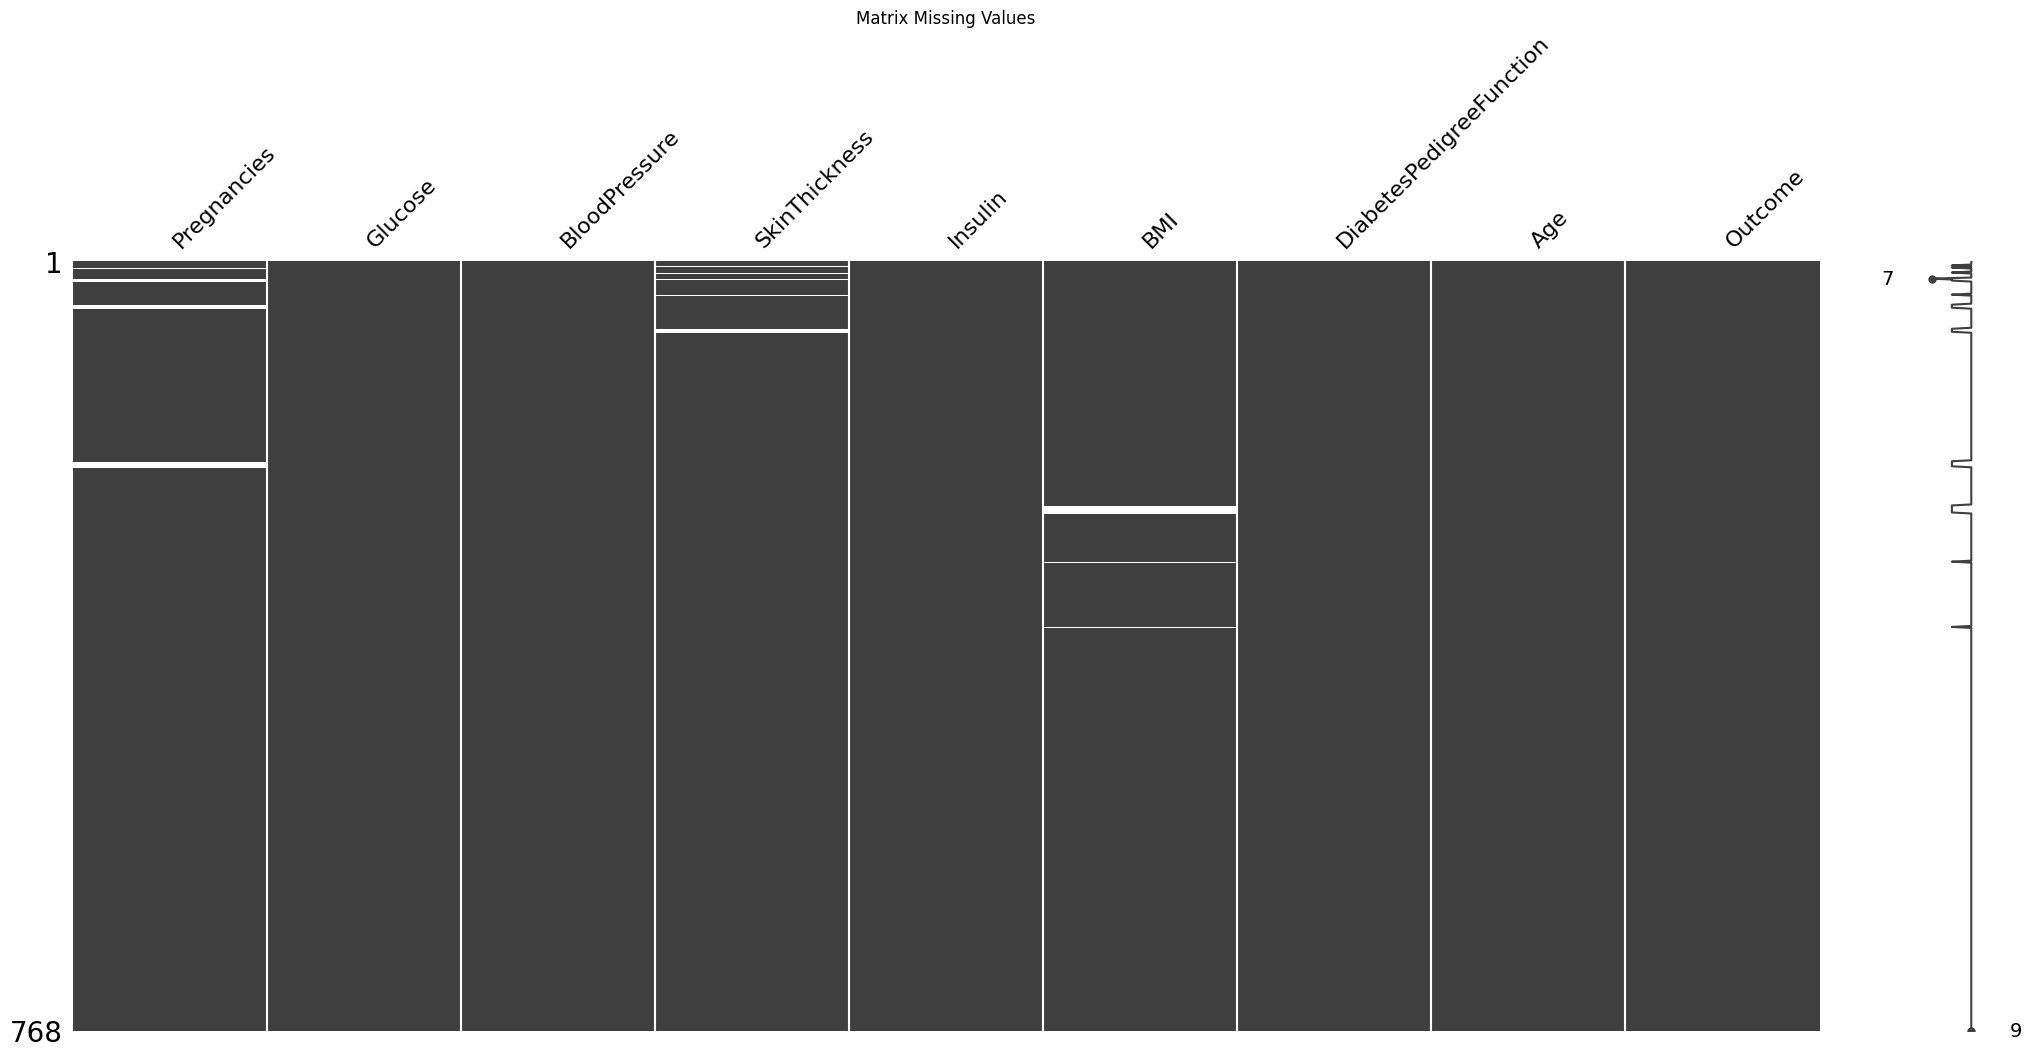

In [59]:
plt.figure(figsize=(10,6))
msno.matrix(df)
plt.title("Matrix Missing Values")

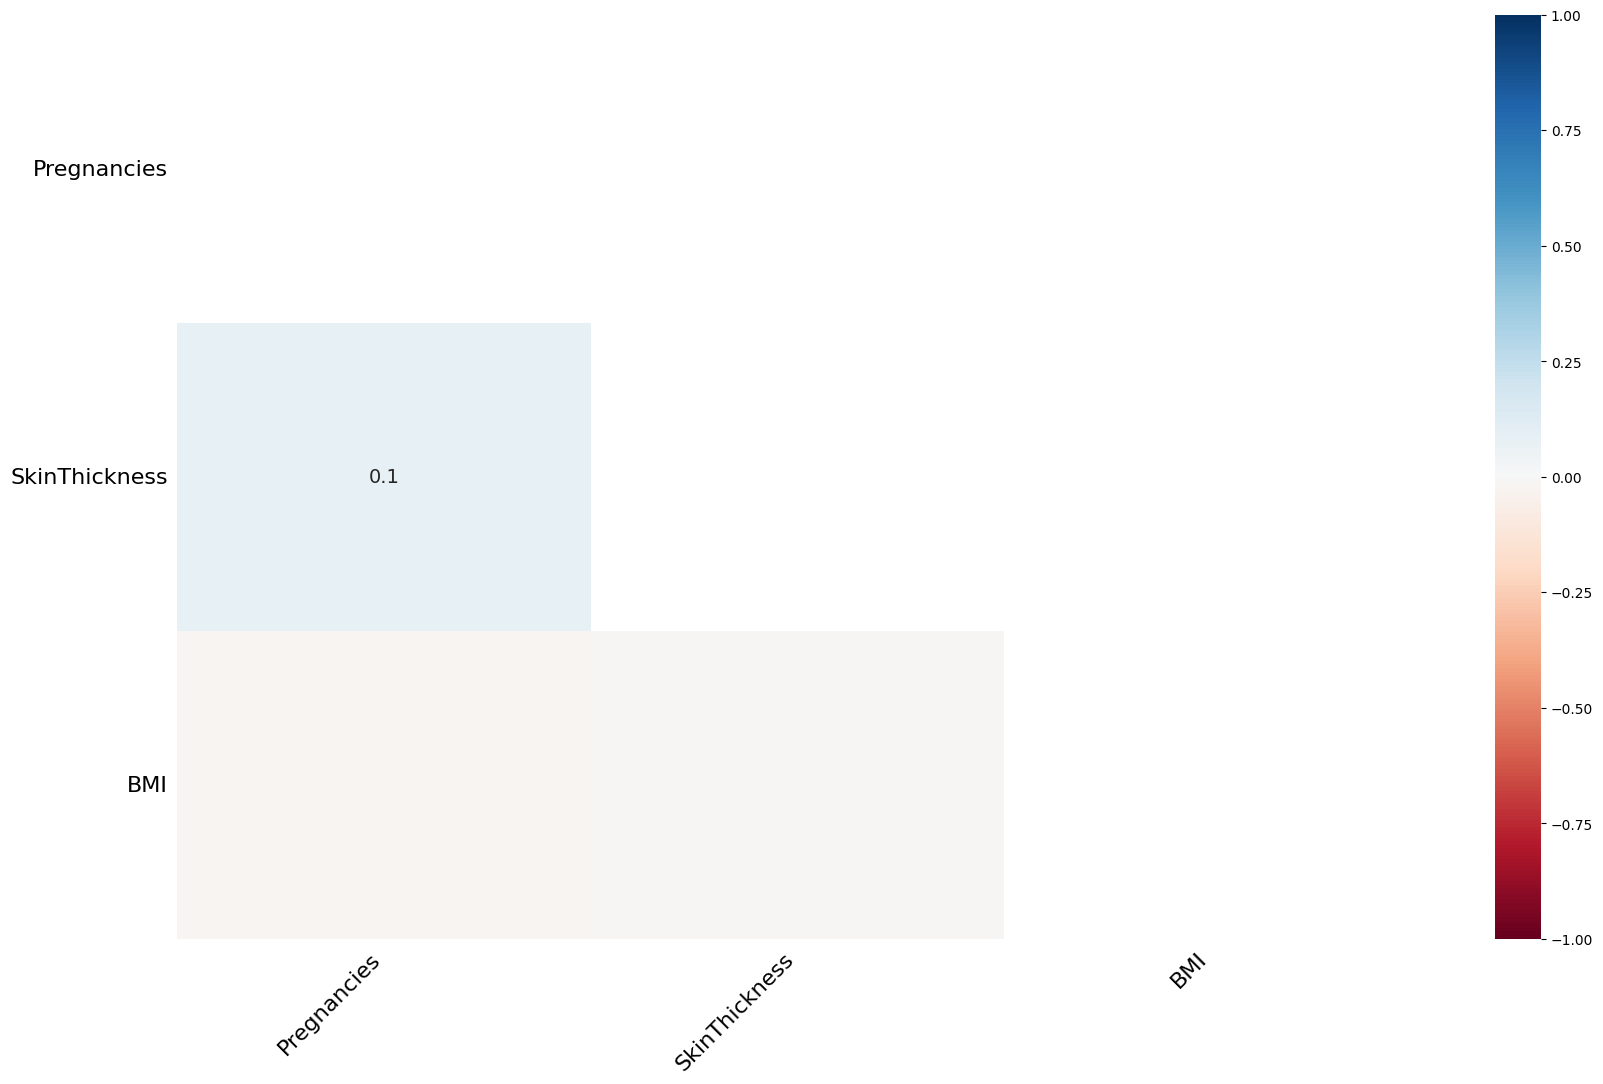

In [60]:
msno.heatmap(df)
plt.show()
#moze da se zabalezi deka ima weak correlation megju pregnancies i skinThickness

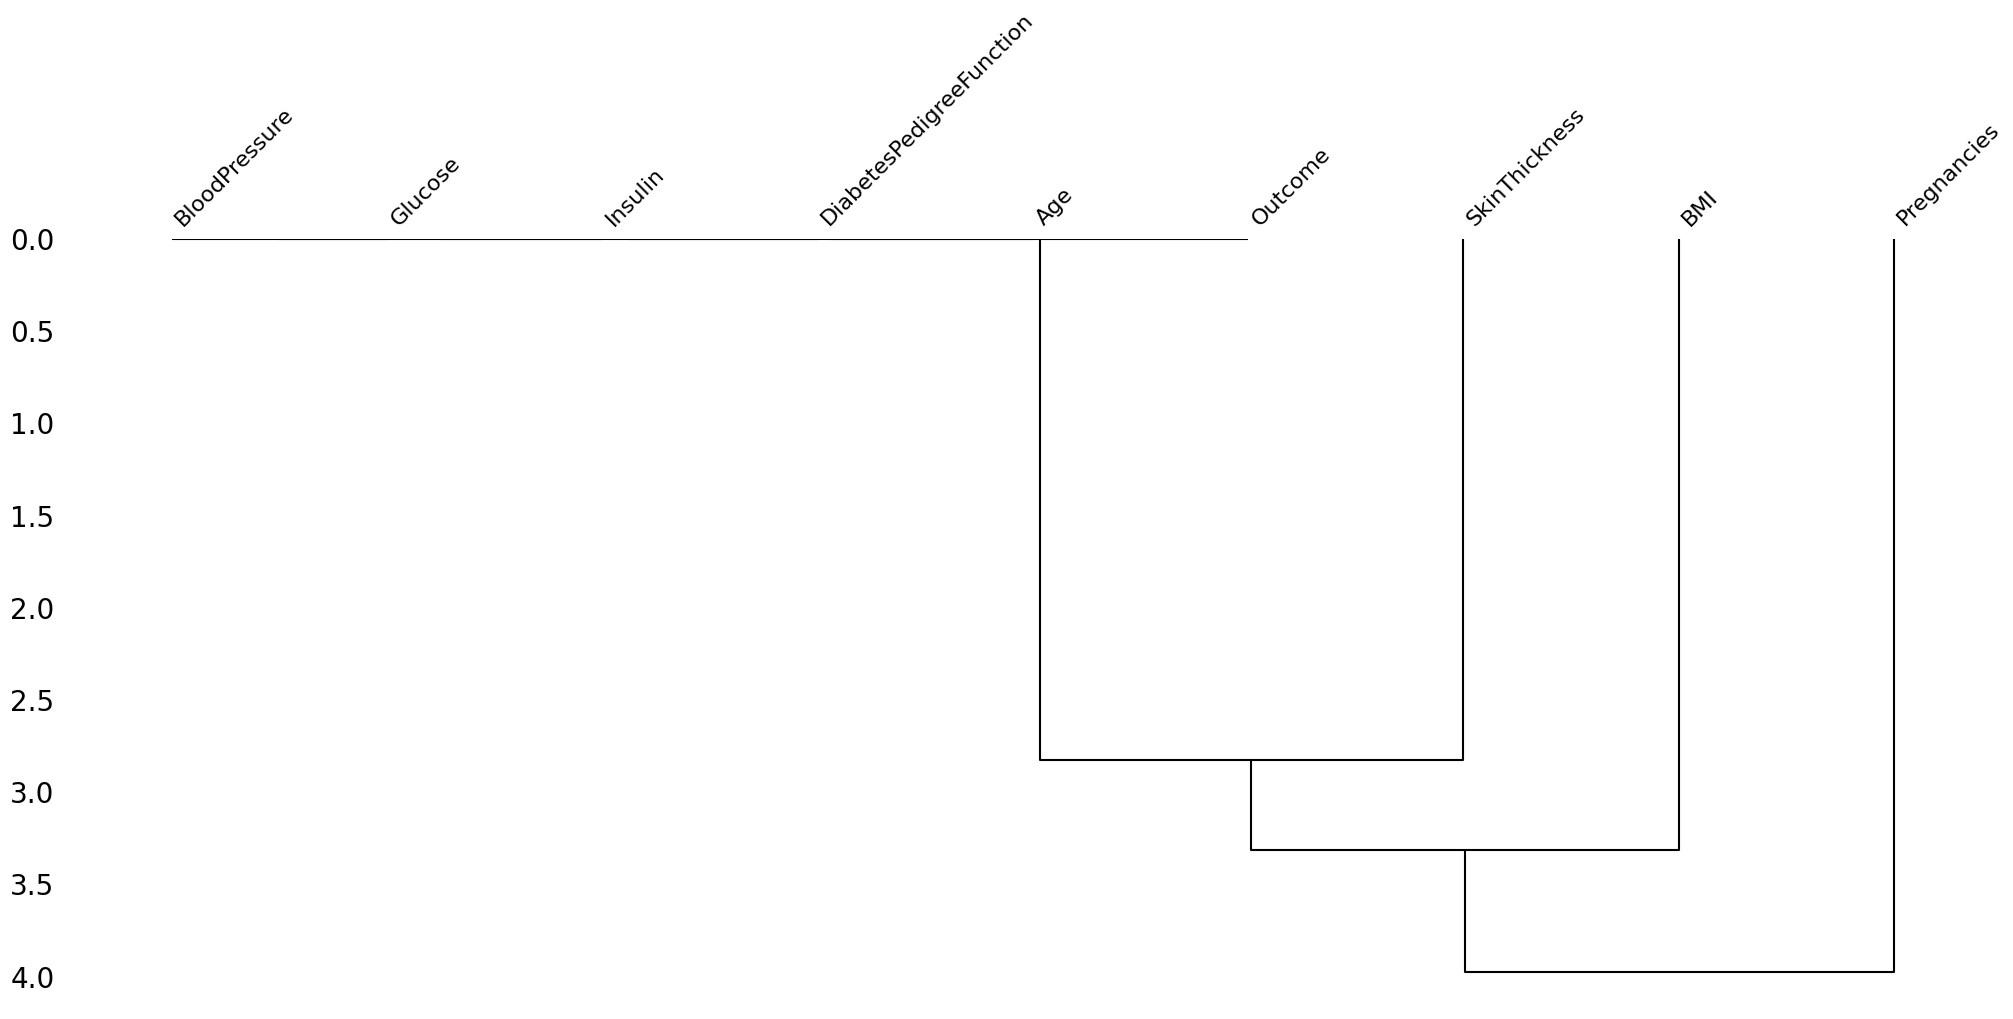

In [61]:
msno.dendrogram(df)
plt.show()

## <font color = 'Orange'>Handle the missing values</font>

In [62]:
df_cleaned=df.copy()
df_cleaned.Pregnancies=df_cleaned.Pregnancies.fillna(df_cleaned.Pregnancies.mean())
constant_imputer=SimpleImputer(strategy='constant',fill_value=0)
df_cleaned['BMI']=constant_imputer.fit_transform([df_cleaned['BMI']])[0]
df_cleaned=df_cleaned.dropna(subset=['SkinThickness'],axis=0)
df_cleaned.isnull().sum()



,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


## <font color = 'Orange'>Save the new Dataset(.csv) without the missing values</font>

In [63]:
df_cleaned.to_csv('diabetes_cleaned.csv',index=False)


Print the first rows of your final Dataset

In [64]:
df_cleaned.head(10)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6.000000,148,72,35.0,0,33.6,0.627,50,1
1,1.000000,85,66,29.0,0,26.6,0.351,31,0
2,8.000000,183,64,0.0,0,23.3,0.672,32,1
3,1.000000,89,66,23.0,94,28.1,0.167,21,0
4,0.000000,137,40,35.0,168,43.1,2.288,33,1
6,3.000000,78,50,32.0,88,31.0,0.248,26,1
7,3.864721,115,0,0.0,0,35.3,0.134,29,0
8,2.000000,197,70,45.0,543,30.5,0.158,53,1
9,8.000000,125,96,0.0,0,0.0,0.232,54,1
10,4.000000,110,92,0.0,0,37.6,0.191,30,0


# <font color='orange'>KNN Classification</font>

##<font color = 'Orange'>Split the dataset for training and testing in ratio 80:20 </font>


In [65]:
# 1. Load data
df = pd.read_csv('diabetes.csv')

# 2. Separate features and target
X = df.drop('Outcome', axis=1)
y = df['Outcome']

# 3. Handle missing values using SimpleImputer
imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X)

# 4. Scale the features
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_imputed)

# 5. Split the dataset (80:20)
X_train, X_test, y_train, y_test = train_test_split(X_scaled,
                                                    y,
                                                    test_size=0.2,
                                                    random_state=42)
print("Training set size",X_train.shape[0])
print("Testing set size",X_test.shape[0])

Training set size 614
Testing set size 154


## <font color = 'Orange'>Initialize the KNN Classification model, and use the fit function for training the model</font>

In [66]:
knn_classifier = KNeighborsClassifier(n_neighbors=5)
knn_classifier.fit(X_train, y_train)
print("KNN model trained successfully")


KNN model trained successfully


## <font color = 'Orange'>Predict the outcomes for X test</font>

In [67]:
y_pred = knn_classifier.predict(X_test)

## <font color = 'Orange'>See the model performance, by using sklearn metrics for classification</font>



In [68]:
print("\nModel Performance Metrics:")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nAccuracy Score:", accuracy_score(y_test, y_pred))



Model Performance Metrics:

Confusion Matrix:
[[76 23]
 [27 28]]

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.77      0.75        99
           1       0.55      0.51      0.53        55

    accuracy                           0.68       154
   macro avg       0.64      0.64      0.64       154
weighted avg       0.67      0.68      0.67       154


Accuracy Score: 0.6753246753246753
